In [9]:
import numpy as np
import matplotlib.pyplot as plt

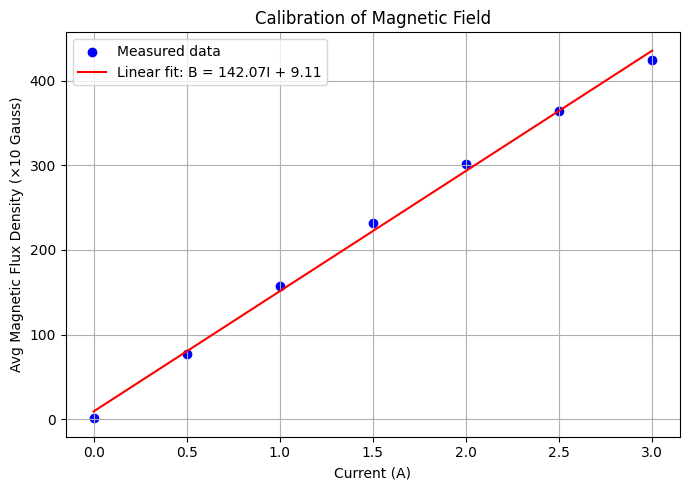

Slope (m): 142.0714
Intercept (c): 9.1071


In [10]:
# Data from Table 1: Calibration of Magnetic field
current = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3])
avg_flux_density = np.array([1, 76.5, 157, 231.5, 301, 364.5, 424])

# Linear fit: B = m*I + c
m, c = np.polyfit(current, avg_flux_density, 1)
fit_line = m * current + c

# Plot
plt.figure(figsize=(7, 5))
plt.scatter(current, avg_flux_density, color='blue', label='Measured data')
plt.plot(current, fit_line, color='red', label=f'Linear fit: B = {m:.2f}I + {c:.2f}')

plt.xlabel('Current (A)')
plt.ylabel('Avg Magnetic Flux Density (×10 Gauss)')
plt.title('Calibration of Magnetic Field')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Slope (m): {m:.4f}")
print(f"Intercept (c): {c:.4f}")

P-type, Rtp=33.7°C: slope = 4.2901 mV/A, intercept = 2.3989 mV
P-type, T=45°C: slope = 4.4571 mV/A, intercept = 2.7667 mV
N-type, Rtp=33.7°C: slope = -1.2600 mV/A, intercept = -1.2400 mV
N-type, T=45°C: slope = -1.4429 mV/A, intercept = -0.9071 mV


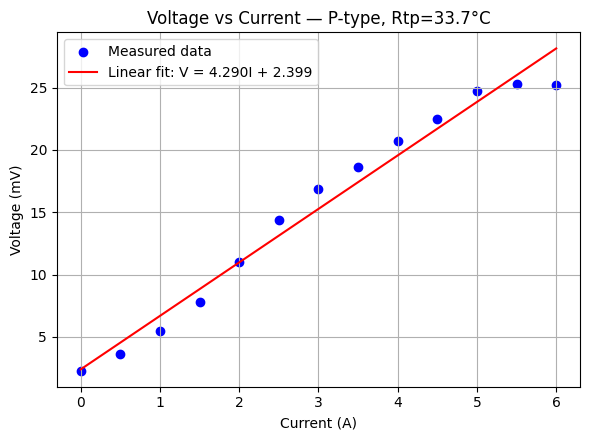

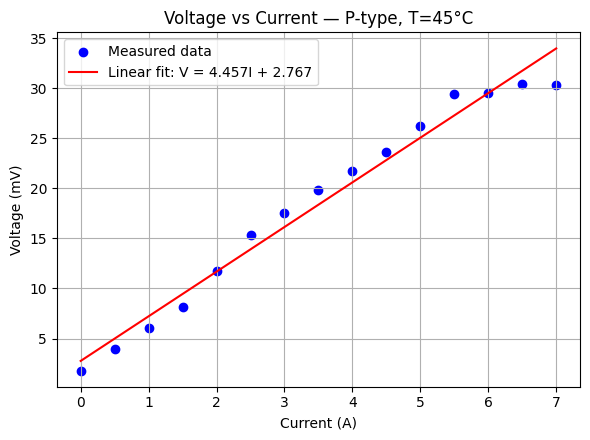

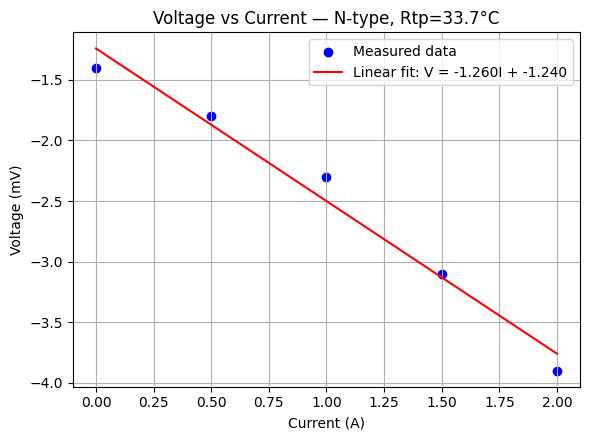

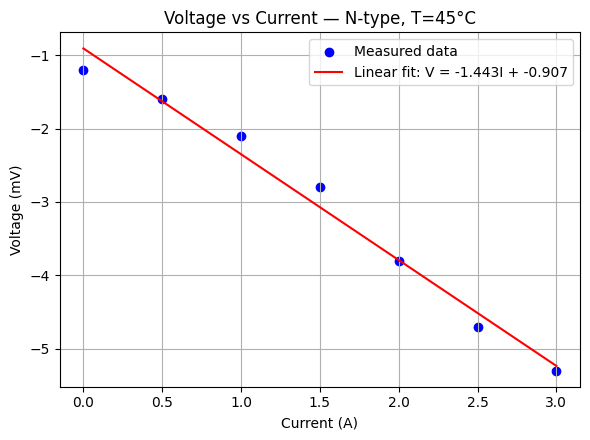

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# --- Table 2: P-type, B=0 ---
current_p = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5, 7])
voltage_p_rtp = np.array([2.3, 3.6, 5.5, 7.8, 11, 14.4, 16.9, 18.6, 20.7, 22.5, 24.7, 25.3, 25.2, np.nan, np.nan])
voltage_p_t45 = np.array([1.8, 4, 6.1, 8.2, 11.7, 15.3, 17.5, 19.8, 21.7, 23.6, 26.2, 29.4, 29.5, 30.4, 30.3])

# --- Table 2': N-type, B=0 ---
current_n = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3])
voltage_n_rtp = np.array([-1.4, -1.8, -2.3, -3.1, -3.9, np.nan, np.nan])
voltage_n_t45 = np.array([-1.2, -1.6, -2.1, -2.8, -3.8, -4.7, -5.3])

datasets = [
    ("P-type, Rtp=33.7°C", current_p, voltage_p_rtp),
    ("P-type, T=45°C", current_p, voltage_p_t45),
    ("N-type, Rtp=33.7°C", current_n, voltage_n_rtp),
    ("N-type, T=45°C", current_n, voltage_n_t45),
]

for name, I, V in datasets:
    # drop NaN pairs before fitting
    mask = ~np.isnan(V)
    I_valid, V_valid = I[mask], V[mask]

    m, c = np.polyfit(I_valid, V_valid, 1)
    fit_line = m * I_valid + c

    plt.figure(figsize=(6, 4.5))
    plt.scatter(I_valid, V_valid, color='blue', label='Measured data')
    plt.plot(I_valid, fit_line, color='red', label=f'Linear fit: V = {m:.3f}I + {c:.3f}')

    plt.xlabel('Current (A)')
    plt.ylabel('Voltage (mV)')
    plt.title(f'Voltage vs Current — {name}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    fname = name.lower().replace(", ", "_").replace("=", "").replace("°", "").replace(" ", "_")
    print(f"{name}: slope = {m:.4f} mV/A, intercept = {c:.4f} mV")

P-type, 1A(1570G), Rtp=33.7C: slope = 2.3762 mV/A, intercept = 1.3273 mV
P-type, 1A(1570G), T=45C: slope = 2.1132 mV/A, intercept = 5.3423 mV
P-type, 2A(3010G), Rtp=33.7C: slope = 4.5811 mV/A, intercept = 2.3864 mV
P-type, 2A(3010G), T=45C: slope = 4.0259 mV/A, intercept = 5.8742 mV
N-type, 1A(1570G), Rtp=33.7C: slope = -1.8600 mV/A, intercept = -1.5600 mV
N-type, 1A(1570G), T=45C: slope = -1.2114 mV/A, intercept = -1.5524 mV
N-type, 2A(3010G), Rtp=33.7C: slope = -4.2600 mV/A, intercept = -2.6400 mV
N-type, 2A(3010G), T=45C: slope = -4.2873 mV/A, intercept = -1.6636 mV


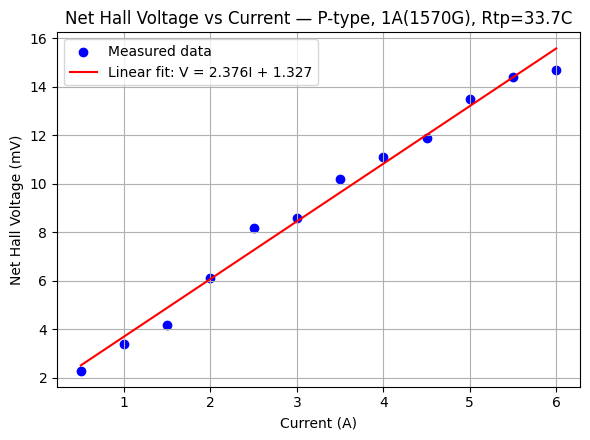

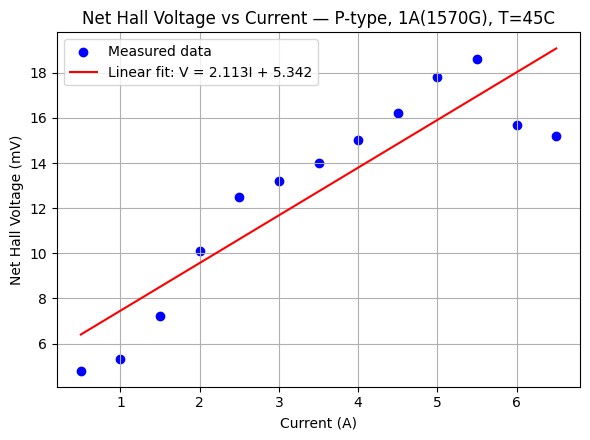

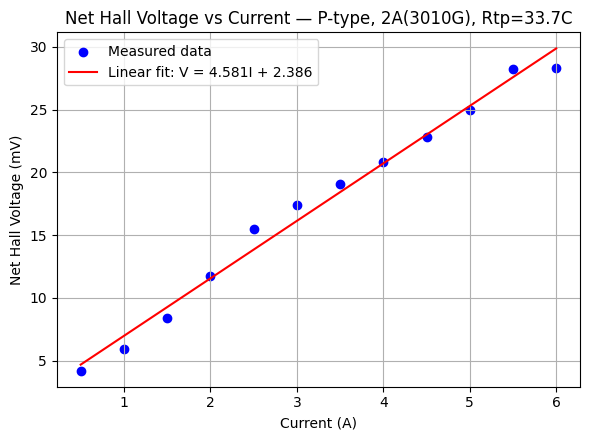

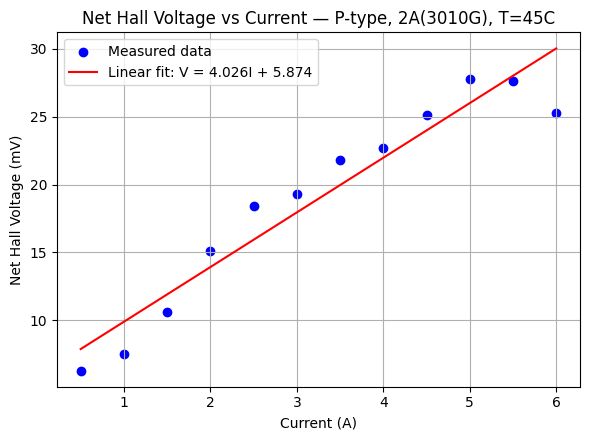

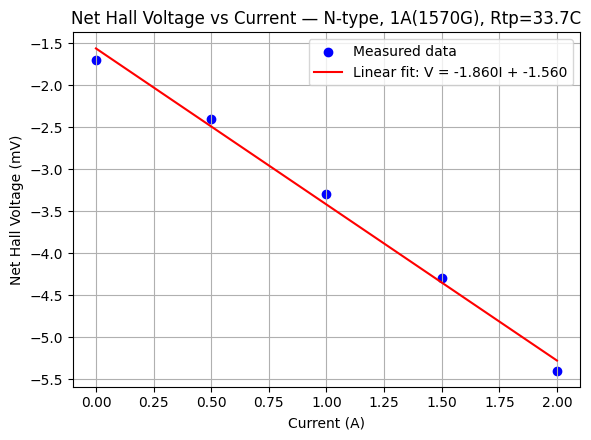

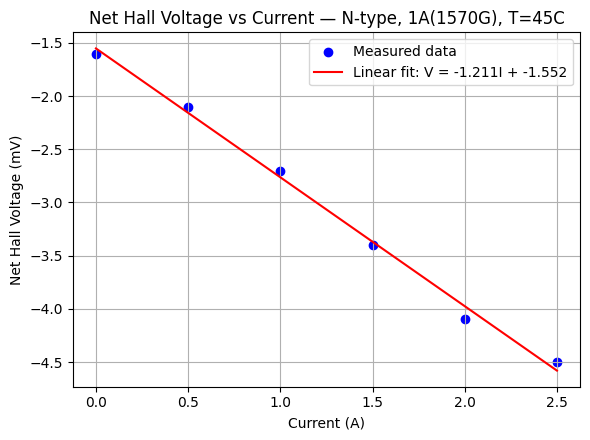

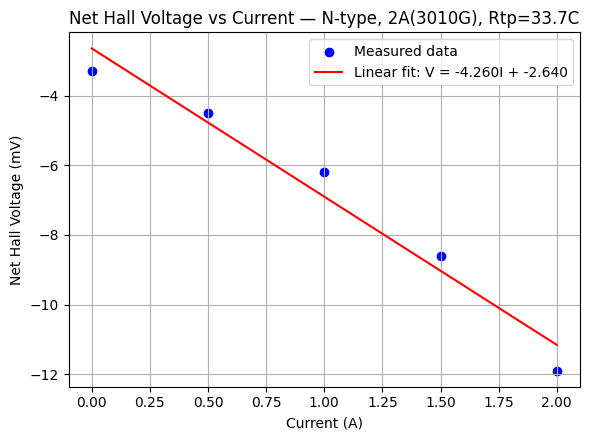

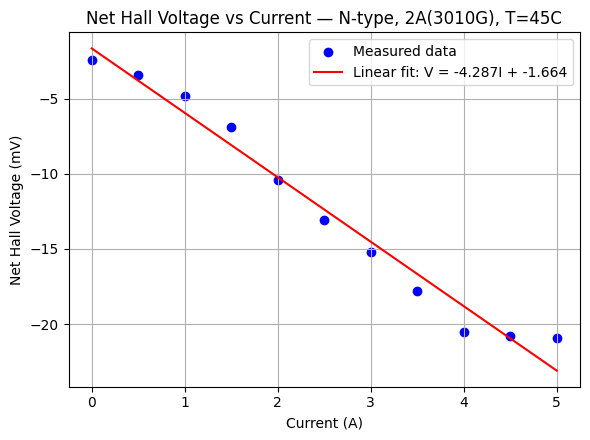

In [12]:
# Table 3: Voltage as a function of sample current (B non-zero)

# --- P-type ---
current_p = np.array([0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5, 5.5, 6, 6.5])

# 1A, 157*10 Gauss (1570 G), Rtemp=33.7C
net_hv_p_1A_rtp = np.array([2.3, 3.4, 4.2, 6.1, 8.2, 8.6, 10.2, 11.1, 11.9, 13.5, 14.4, 14.7, np.nan])
# 1A, 1570 G, T=45C
net_hv_p_1A_t45 = np.array([4.8, 5.3, 7.2, 10.1, 12.5, 13.2, 14, 15, 16.2, 17.8, 18.6, 15.7, 15.2])

# 2A, 3010 Gauss, Rtemp=33.7C
net_hv_p_2A_rtp = np.array([4.2, 5.9, 8.4, 11.7, 15.5, 17.4, 19.1, 20.8, 22.8, 25, 28.2, 28.3, np.nan])
# 2A, 3010 G, T=45C
net_hv_p_2A_t45 = np.array([6.3, 7.5, 10.6, 15.1, 18.4, 19.3, 21.8, 22.7, 25.1, 27.8, 27.6, 25.3, np.nan])

# --- N-type ---
current_n = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5])

# 1A, 1570 G, Rtemp=33.7C
net_hv_n_1A_rtp = np.array([-1.7, -2.4, -3.3, -4.3, -5.4, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan])
# 1A, 1570 G, T=45C
net_hv_n_1A_t45 = np.array([-1.6, -2.1, -2.7, -3.4, -4.1, -4.5, np.nan, np.nan, np.nan, np.nan, np.nan])

# 2A, 3010 G, Rtemp=33.7C
net_hv_n_2A_rtp = np.array([-3.3, -4.5, -6.2, -8.6, -11.9, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan])
# 2A, 3010 G, T=45C
net_hv_n_2A_t45 = np.array([-2.4, -3.4, -4.8, -6.9, -10.4, -13.1, -15.2, -17.8, -20.5, -20.8, -20.9])
# note: only first 7 values line up cleanly with current_n(0..3); table shows more T=45 rows
# extend current_n for T45 N-type series which has more points
current_n_t45 = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 4.5, 5])

datasets = [
    ("P-type, 1A(1570G), Rtp=33.7C", current_p, net_hv_p_1A_rtp),
    ("P-type, 1A(1570G), T=45C",     current_p, net_hv_p_1A_t45),
    ("P-type, 2A(3010G), Rtp=33.7C", current_p, net_hv_p_2A_rtp),
    ("P-type, 2A(3010G), T=45C",     current_p, net_hv_p_2A_t45),
    ("N-type, 1A(1570G), Rtp=33.7C", current_n, net_hv_n_1A_rtp),
    ("N-type, 1A(1570G), T=45C",     current_n, net_hv_n_1A_t45),
    ("N-type, 2A(3010G), Rtp=33.7C", current_n, net_hv_n_2A_rtp),
    ("N-type, 2A(3010G), T=45C",     current_n_t45, net_hv_n_2A_t45),
]

for name, I, V in datasets:
    mask = ~np.isnan(V)
    I_valid, V_valid = I[mask], V[mask]

    m, c = np.polyfit(I_valid, V_valid, 1)
    fit_line = m * I_valid + c

    plt.figure(figsize=(6, 4.5))
    plt.scatter(I_valid, V_valid, color='blue', label='Measured data')
    plt.plot(I_valid, fit_line, color='red', label=f'Linear fit: V = {m:.3f}I + {c:.3f}')

    plt.xlabel('Current (A)')
    plt.ylabel('Net Hall Voltage (mV)')
    plt.title(f'Net Hall Voltage vs Current — {name}')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    fname = name.lower().replace(", ", "_").replace("(", "").replace(")", "").replace("=", "").replace(" ", "_")

    print(f"{name}: slope = {m:.4f} mV/A, intercept = {c:.4f} mV")